# Cybertron-Interp: Mechanistic Interpretability Notebook

> **Prerequisite Note:** Ensure you have read through our Readme as it provides valuable details on the workflow you will be going through below.

Stage 1 Fine Tuning:   

In [52]:
from datasets import Dataset
from transformers import (
    DataCollatorForLanguageModeling,
    GPT2LMHeadModel,
    GPT2Tokenizer,
    Trainer,
    TrainingArguments,
)

# Note: This uses a lightweight sample corpus and saves to a sample weights folder.
# If you wish to download the full fine-tuned weights themselves, I've made them available here: https://huggingface.co/dhanson5/cybertron-gpt2-lore

# Load tokenizer and base GPT-2 weights
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
if tokenizer.pad_token is None:
  tokenizer.pad_token = tokenizer.eos_token

model = GPT2LMHeadModel.from_pretrained("gpt2")

# Load sample lore dataset
print("Loading and tokenizing sample dataset...")
with open("sample_corpus.txt", "r", encoding="utf-8") as f:
  text_data = f.read()

encodings = tokenizer(text_data, return_special_tokens_mask=False)

block_size = 128
input_ids = []
for i in range(0, len(encodings["input_ids"]) - block_size + 1, block_size):
  input_ids.append(encodings["input_ids"][i : i + block_size])

train_dataset = Dataset.from_dict({"input_ids": input_ids})

data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

# Configure training arguments for the sample run
sample_weights_dir = "./sample_transformers_weights"
training_args = TrainingArguments(
    output_dir=sample_weights_dir,
    num_train_epochs=1,
    per_device_train_batch_size=4,
    save_steps=500,
    save_total_limit=2,
    logging_steps=50,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    data_collator=data_collator,
    train_dataset=train_dataset,
)

# 4. Start fine-tuning
print("Starting fine-tuning...")
trainer.train()

# 5. Save the fine-tuned sample checkpoint
model.save_pretrained(sample_weights_dir)
tokenizer.save_pretrained(sample_weights_dir)
print(f"Sample fine-tuning complete and weights saved to {sample_weights_dir}!")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading and tokenizing sample dataset...
Starting fine-tuning...


Step,Training Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Sample fine-tuning complete and weights saved to ./sample_transformers_weights!


Inference Test:  

In [61]:
from transformers import GPT2LMHeadModel, GPT2Tokenizer

tokenizer = GPT2Tokenizer.from_pretrained("./sample_transformers_weights")
model = GPT2LMHeadModel.from_pretrained("./sample_transformers_weights")

prompt = "Optimus Prime is a"
inputs = tokenizer(prompt, return_tensors="pt")

bad_words_ids = [
    tokenizer.encode(" (", add_special_tokens=False),
    tokenizer.encode("(", add_special_tokens=False),
]

outputs = model.generate(
    **inputs,
    max_length=25,
    do_sample=True,
    temperature=0.5,
    top_p=0.9,
    repetition_penalty=1.2,
    no_repeat_ngram_size=3,
    pad_token_id=tokenizer.eos_token_id,
    bad_words_ids=bad_words_ids,
)

print(tokenizer.decode(outputs[0], skip_special_tokens=True))

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Optimus Prime is a great game, but it's not really about the story. It has no real character development and nothing


Stage 2:   Attention Pattern Detection & Routing Analysis:  

In [54]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import circuitsvis as cv
from transformers import GPT2LMHeadModel, GPT2Tokenizer

# We are using OpenAI's GPT2 to conduct this project.  
# Since it is more basic, we are able to more easily interpret its cognitive output.  
# To get exposed to additional information, we set the model config to "eager".
# To speed up operations, we are using an Nvidia GPU and PyTorch's GPU-enabled config.

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_id = "gpt2"  # Set GPT-2 as our baseline model
tokenizer = GPT2Tokenizer.from_pretrained(model_id) 
model = GPT2LMHeadModel.from_pretrained(model_id, attn_implementation="eager").to(device)
model.eval() # Set model to evaluation mode (disabling dropout/batchnorm updates)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [55]:
# Tokenize the prompt and return attention tensor 
prompt = "Optimus Prime is"

inputs = tokenizer(prompt, return_tensors="pt").to(device)
tokens = [tokenizer.decode([t]) for t in inputs["input_ids"][0]]

with torch.no_grad():
    outputs = model(**inputs, output_attentions=True)

# Stack attention weights: [num_layers, batch, heads, q_pos, k_pos]
# We can see how the input string is broken down into subwords (tokens)
all_attentions = torch.stack(outputs.attentions)
print(f"Prompt tokens: {tokens}")
print(f"Attention tensor shape: {all_attentions.shape}")

Prompt tokens: ['Opt', 'imus', ' Prime', ' is']
Attention tensor shape: torch.Size([12, 1, 12, 4, 4])


In [56]:
# Generate a response to see how the model responds to the prompt

# Ensure inputs stay on the correct device for downstream cells
inputs = tokenizer(prompt, return_tensors="pt").to(device)
input_ids = inputs["input_ids"]

with torch.no_grad():
    output_ids = model.generate(
        input_ids,
        max_new_tokens=20,
        do_sample=True,
        temperature=0.7,
        repetition_penalty=1.2,
        pad_token_id=tokenizer.eos_token_id
    )

response_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)
print(f"Model Response:\n{response_text}")

Model Response:
Optimus Prime is available at: http://www.amazon-us/gp/$product_id=141160


Stage 3:  Activation Caching & Tensor Influencing

Residual Stream Layer 0 vs Layer  3 Cosine Similarity: 0.9289
Residual Stream Layer 0 vs Layer  6 Cosine Similarity: 0.8590
Residual Stream Layer 0 vs Layer  9 Cosine Similarity: 0.7091
Residual Stream Layer 0 vs Layer 11 Cosine Similarity: 0.4583


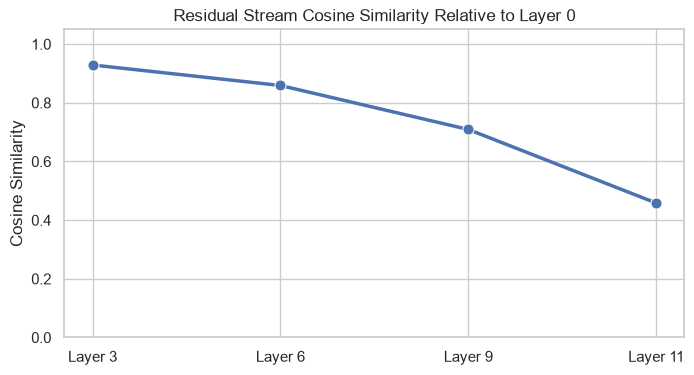

In [57]:
# We capture the model's hidden states at each layer to measure how much the meaning of the tokens 
# shifts from the first layer to the last.

cache = {"resid": {}}

def register_resid_hooks():
    handles = []
    for idx, block in enumerate(model.transformer.h):
        handles.append(block.register_forward_hook(
            lambda m, i, o, l=idx: cache["resid"].update({l: (o[0] if isinstance(o, tuple) else o).squeeze(0).detach()})
        ))
    return handles

# Here, we register PyTorch forward hooks on every transformer block 
# to intercept and cache these hidden states mid-pass 

handles = register_resid_hooks()
with torch.no_grad():
    _ = model(**inputs)
for h in handles:
    h.remove()

# Compute cosine compared with Layer 0 for the final token
target_layers = [3, 6, 9, 11]
resid_sims = [F.cosine_similarity(cache["resid"][0][-1], cache["resid"][l][-1], dim=0).item() for l in target_layers]

for l, sim in zip(target_layers, resid_sims):
    print(f"Residual Stream Layer 0 vs Layer {l:2d} Cosine Similarity: {sim:.4f}")

# Visualize representation drift across depth
# We examine how the residual stream hidden states
# lower cosine scores mean deeper layers have diverged from the initial embeddings.

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 4))
sns.lineplot(x=[f"Layer {l}" for l in target_layers], y=resid_sims, marker="o", linewidth=2.5, markersize=8)
plt.title("Residual Stream Cosine Similarity Relative to Layer 0")
plt.ylabel("Cosine Similarity")
plt.ylim(0, 1.05)
plt.show()

Stage 4:  Vector Visualizations & Analysis

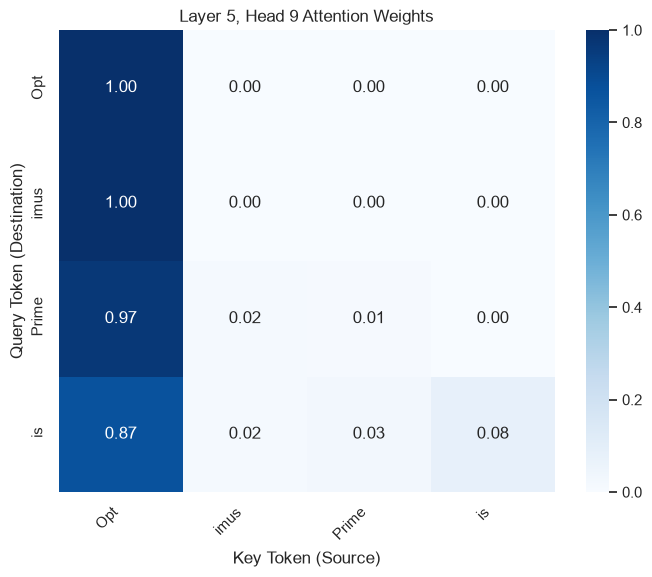

In [58]:
# Seaborn visual heatmap for a single head (Layer 5, Head 9)
# we can see how each token is being processed by the attention weights

matrix = all_attentions[5, 0, 9].detach().cpu().numpy()
plt.figure(figsize=(8, 6))
sns.heatmap(matrix, xticklabels=tokens, yticklabels=tokens, annot=True, fmt=".2f", cmap="Blues")
plt.title("Layer 5, Head 9 Attention Weights")
plt.xlabel("Key Token (Source)")
plt.ylabel("Query Token (Destination)")
plt.xticks(rotation=45, ha="right")
plt.show()

Stage 5:  Direct Logit Attribution & The Logit Lens

In [59]:
# We look inside each layer's hidden thoughts to see what words the model is predicting. 

def run_logit_lens(token_idx, label):
    print(f"\nLogit Lens progression for '{label}' (index {token_idx}):")
    for layer_idx in range(len(model.transformer.h)):
        h_state = cache["resid"][layer_idx][token_idx]
        logits = model.lm_head(model.transformer.ln_f(h_state))
        top_token = tokenizer.decode([logits.argmax().item()])
        print(f"  Layer {layer_idx:2d} -> Top Prediction: '{top_token}'")

# Trace initial and final token positions
# pretty cool that we can see what our model is predicting based on the input string
run_logit_lens(0, tokens[0])
run_logit_lens(len(tokens) - 1, tokens[-1])


Logit Lens progression for 'Opt' (index 0):
  Layer  0 -> Top Prediction: 'ical'
  Layer  1 -> Top Prediction: ' the'
  Layer  2 -> Top Prediction: ','
  Layer  3 -> Top Prediction: ','
  Layer  4 -> Top Prediction: ','
  Layer  5 -> Top Prediction: ','
  Layer  6 -> Top Prediction: ','
  Layer  7 -> Top Prediction: ','
  Layer  8 -> Top Prediction: ','
  Layer  9 -> Top Prediction: ','
  Layer 10 -> Top Prediction: ','
  Layer 11 -> Top Prediction: '.'

Logit Lens progression for ' is' (index 3):
  Layer  0 -> Top Prediction: ' not'
  Layer  1 -> Top Prediction: ' not'
  Layer  2 -> Top Prediction: ' not'
  Layer  3 -> Top Prediction: ' now'
  Layer  4 -> Top Prediction: ' also'
  Layer  5 -> Top Prediction: ' also'
  Layer  6 -> Top Prediction: ' now'
  Layer  7 -> Top Prediction: ' now'
  Layer  8 -> Top Prediction: ' not'
  Layer  9 -> Top Prediction: ' a'
  Layer 10 -> Top Prediction: ' a'
  Layer 11 -> Top Prediction: ' a'


Stage 6:  Causal Intervention & Model Steering

In [60]:
# Causal Intervention: Testing cause-and-effect by interrupting the model's stream of thought.

# Activation Patching: We interrupt one thought process mid-stream and replace its internal state 
# with one from a different prompt to see how it changes the outcome.

clean_inputs = tokenizer("Optimus Prime is the commander of the", return_tensors="pt").to(device)
corrupted_inputs = tokenizer("Megatron is the leader of the", return_tensors="pt").to(device)

clean_state = {}
h_clean = model.transformer.h[9].register_forward_hook(
    lambda m, i, o: clean_state.update({"val": (o[0] if isinstance(o, tuple) else o).detach().clone()})
)
with torch.no_grad():
    _ = model(**clean_inputs)
h_clean.remove()

def patch_hook(module, input, output):
    is_tuple = isinstance(output, tuple)
    tensor = output[0] if is_tuple else output
    tensor[:, -1, :] = clean_state["val"][:, -1, :]
    return (tensor,) + output[1:] if is_tuple else tensor

h_patch = model.transformer.h[9].register_forward_hook(patch_hook)
with torch.no_grad():
    patched_out = model(**corrupted_inputs)
h_patch.remove()

print(f"Corrupted prompt prediction after patching Layer 9: '{tokenizer.decode([patched_out.logits[0, -1, :].argmax().item()])}'")

# Steering Vectors: Extract concept difference vector and steer text generation

pos_inputs = tokenizer("Optimus Prime is the leader of the", return_tensors="pt").to(device)
base_inputs = tokenizer("Megatron is the leader of the", return_tensors="pt").to(device)
vecs = {}

for key, inp in [("pos", pos_inputs), ("base", base_inputs)]:
    h = model.transformer.h[9].register_forward_hook(
        lambda m, i, o, k=key: vecs.update({k: (o[0] if isinstance(o, tuple) else o)[0, -1, :].detach().clone()})
    )
    with torch.no_grad():
        _ = model(**inp)
    h.remove()

steering_vector = vecs["pos"] - vecs["base"]
alpha = 0.8

def steering_hook(module, input, output):
    is_tuple = isinstance(output, tuple)
    tensor = output[0] if is_tuple else output
    tensor[:, -1, :] += alpha * steering_vector
    return (tensor,) + output[1:] if is_tuple else tensor

# We inject the Optimus-vs-Megatron steering vector into the residual stream while generating on an unrelated prompt
# to observe how the model's continuation shifts toward the steered concept.

test_ids = tokenizer("The giant alien robot transformed into a truck and said,", return_tensors="pt").to(device)
h_steer = model.transformer.h[9].register_forward_hook(steering_hook)
with torch.no_grad():
    gen_ids = model.generate(**test_ids, max_new_tokens=30, do_sample=True, temperature=0.7, repetition_penalty=1.2)
h_steer.remove()

print("\nSteered Generation:")
print(tokenizer.decode(gen_ids[0], skip_special_tokens=True))

Corrupted prompt prediction after patching Layer 9: ' Autob'

Steered Generation:
The giant alien robot transformed into a truck and said, "What are you doing here?"
"Go back to the Earth. Your life is over."
I looked at him in surprise as he leaned
